In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    ConfusionMatrixDisplay, roc_auc_score
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

In [2]:
rng = np.random.default_rng(RANDOM_STATE)
n = 1200

tenure_months = rng.integers(1, 73, n).astype(float)
monthly_spend = rng.normal(950, 280, n).clip(200, 2500)
support_tickets = rng.poisson(2.0, n).astype(float)
last_login_days = rng.integers(0, 61, n).astype(float)
plan_type = rng.choice(["Basic", "Standard", "Premium"], size=n, p=[0.45, 0.40, 0.15])
contract = rng.choice(["Monthly", "Annual"], size=n, p=[0.65, 0.35])
region = rng.choice(["North", "South", "East", "West"], size=n)

logit = (
    1.1
    - 0.035 * tenure_months
    + 0.025 * last_login_days
    + 0.30 * support_tickets
    + 0.45 * (contract == "Monthly")
    + 0.35 * (plan_type == "Basic")
)
prob = 1 / (1 + np.exp(-logit))
churned = rng.binomial(1, prob)

df = pd.DataFrame({
    "tenure_months": tenure_months,
    "monthly_spend": monthly_spend.round(2),
    "support_tickets": support_tickets,
    "last_login_days": last_login_days,
    "plan_type": plan_type,
    "contract": contract,
    "region": region,
    "churned": churned
})

for col, frac in {
    "monthly_spend": 0.06,
    "support_tickets": 0.04,
    "plan_type": 0.03,
    "region": 0.025
}.items():
    mask = rng.random(n) < frac
    df.loc[mask, col] = np.nan

df.head()


,tenure_months,monthly_spend,support_tickets,last_login_days,plan_type,contract,region,churned
0,7.0,1299.43,3.0,21.0,Standard,Monthly,South,1
1,56.0,879.30,3.0,8.0,Basic,Annual,West,1
2,48.0,NaN,3.0,32.0,Standard,Monthly,West,1
3,32.0,275.22,1.0,8.0,NaN,Monthly,North,0
4,32.0,626.22,0.0,56.0,Premium,Annual,NaN,1


In [3]:
print("Shape:", df.shape)
print("\\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))
print("\\nTarget balance:")
display(df["churned"].value_counts(normalize=True).rename("proportion").to_frame())


Shape: (1200, 8)
\nData types:


,dtype
tenure_months,float64
monthly_spend,float64
support_tickets,float64
last_login_days,float64
plan_type,str
contract,str
region,str
churned,int64


\nMissing values:


,missing_count
tenure_months,0
monthly_spend,65
support_tickets,40
last_login_days,0
plan_type,33
contract,0
region,30
churned,0


\nTarget balance:


,proportion
churned,
1,0.800833
0,0.199167


In [4]:
TARGET = "churned"
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Training rows: 960 | Test rows: 240
Numeric features: ['tenure_months', 'monthly_spend', 'support_tickets', 'last_login_days']
Categorical features: ['plan_type', 'contract', 'region']


In [5]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=250,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

model_pipeline


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defau

Accuracy: 0.721
Balanced accuracy: 0.63
ROC-AUC: 0.63
\nClassification report:
              precision    recall  f1-score   support

           0       0.35      0.48      0.41        48
           1       0.86      0.78      0.82       192

    accuracy                           0.72       240
   macro avg       0.61      0.63      0.61       240
weighted avg       0.76      0.72      0.74       240



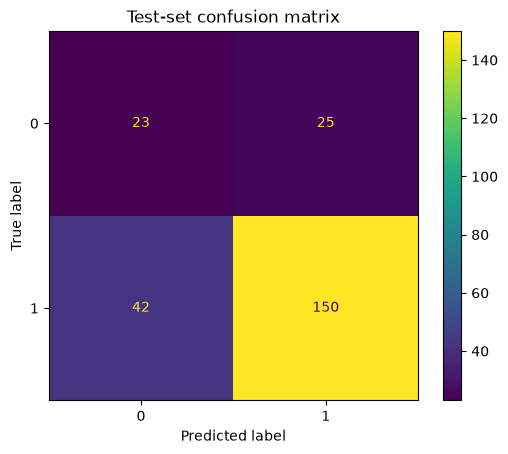

In [6]:
model_pipeline.fit(X_train, y_train)
y_pred = model_pipeline.predict(X_test)
y_prob = model_pipeline.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))
print("\\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Test-set confusion matrix")
plt.show()


In [7]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print("Majority baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 3))
print("Pipeline accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Majority baseline balanced accuracy:", round(balanced_accuracy_score(y_test, baseline_pred), 3))
print("Pipeline balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 3))


Majority baseline accuracy: 0.8
Pipeline accuracy: 0.721
Majority baseline balanced accuracy: 0.5
Pipeline balanced accuracy: 0.63


,feature,importance_mean,importance_std
0,tenure_months,0.099740,0.025061
3,last_login_days,0.065104,0.019207
6,region,0.032813,0.017282
2,support_tickets,0.020052,0.018379
4,plan_type,0.017188,0.011482
1,monthly_spend,0.008594,0.018156
5,contract,-0.006510,0.019110


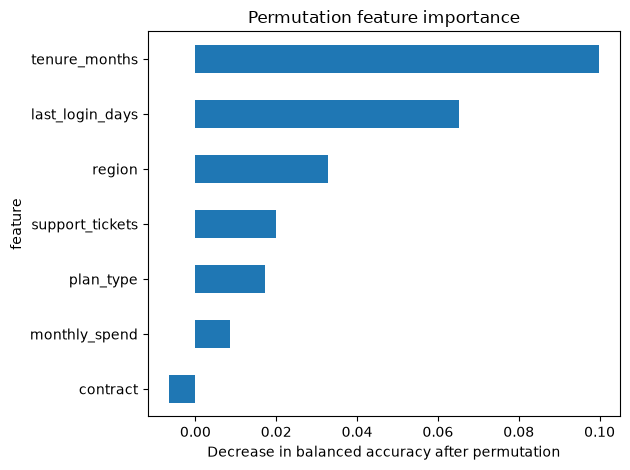

In [8]:
perm = permutation_importance(
    model_pipeline, X_test, y_test,
    n_repeats=10, random_state=RANDOM_STATE,
    scoring="balanced_accuracy"
)
importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance)
importance.sort_values("importance_mean").plot(
    x="feature", y="importance_mean", kind="barh", legend=False,
    xerr=importance.sort_values("importance_mean")["importance_std"]
)
plt.xlabel("Decrease in balanced accuracy after permutation")
plt.title("Permutation feature importance")
plt.tight_layout()
plt.show()


In [9]:
new_customer = pd.DataFrame([{
    "tenure_months": 8,
    "monthly_spend": 720.0,
    "support_tickets": 4,
    "last_login_days": 24,
    "plan_type": "Basic",
    "contract": "Monthly",
    "region": "North"
}])

print("Predicted class:", int(model_pipeline.predict(new_customer)[0]))
print("Predicted class probabilities:", model_pipeline.predict_proba(new_customer)[0])


Predicted class: 1
Predicted class probabilities: [0.10555178 0.89444822]
